In [1]:
import os
from pathlib import Path
from typing import Literal, Optional, List

import numpy as np
import math
import uproot as uproot
import pickle
import pandas as pd
from dataclasses import dataclass, field

import matplotlib.pyplot as plt
plt.rcParams.update({"figure.facecolor": "white", "axes.facecolor": "white"})
import matplotlib.colors
from matplotlib.colors import LinearSegmentedColormap
from matplotlib import ticker
from matplotlib.ticker import (AutoMinorLocator, MultipleLocator)
from matplotlib import gridspec
import seaborn as sns

os.environ["PROJECT_PATH"] = "/home/syebes/lambda-ana"
project_path = Path(os.environ["PROJECT_PATH"])
sys.path.append(str(project_path))
print(project_path/'data'/'df'/'ccqeLambda.df')

/home/syebes/lambda-preselection/data/df/ccqeLambda.df


# Load dfs

In [21]:
df_file = "/home/syebes/cafpyana/lambda.df"
with pd.HDFStore(df_file, 'r') as store:
    print(store.keys())
    

['/cuts_0', '/hdr_0', '/histgenevtdf_0', '/histpotdf_0', '/mcnu_0', '/pot_0', '/split']


In [15]:
mcnu_df = pd.read_hdf(df_file, key='mcnu_0') # Each entry is a subrun
hdr_df = pd.read_hdf(df_file, key='hdr_0') # Each entry is an event
g4_df = pd.read_hdf(df_file, key='g4_0') # 
cuts_df = pd.read_hdf(df_file, key='cuts_0') # Each entry is an slc

In [20]:
g4_id = g4_df['rec', 'true_particles', 'G4ID', '', '', '']
parent = g4_df['rec', 'true_particles', 'parent', '', '', '']
pdg = g4_df['rec', 'true_particles', 'pdg', '', '', '']
start_process = g4_df['rec', 'true_particles', 'start_process', '', '', '']
end_process = g4_df['rec', 'true_particles', 'end_process', '', '', '']

In [17]:
mcnu_df.n_lmbda

__ntuple  entry  rec.mc.nu..index
0         0      0                   0
          1      0                   0
          2      0                   0
          3      0                   1
          4      0                   1
                                    ..
3         137    0                   1
          138    0                   1
          139    0                   1
          140    0                   1
          141    0                   1
Name: n_lmbda, Length: 492, dtype: int64

In [18]:
cols = [(         'n_lmbda',    '',  ''),
            ('is_lambda_signal',    '',  ''),
            (            'n_s0',    '',  ''),
            ('is_sigma0_signal',    '',  ''),]

mcnu_df[cols]

n_lmbda is_lambda_signal n_s0 is_sigma0_signal
                                                                              
                                                                              
__ntuple entry rec.mc.nu..index                                               
0        0     0                      0            False    1             True
         1     0                      0            False    1             True
         2     0                      0            False    1             True
         3     0                      1             True    0            False
         4     0                      1             True    0            False
...                                 ...              ...  ...              ...
3        137   0                      1             True    0            False
         138   0                      1             True    0            False
         139   0                      1             True    0            False
         140   0                      1             True    0            False
         141   0                      1             True    0            False

[492 rows x 4 columns]

In [ ]:
g4_df.columns.to_list()

In [45]:
dec_lambda_mask = (pdg == 3122) & (start_process == 3) & (end_process == 3) & (parent == 3212)

In [46]:
dec_lambda_mask.sum()

0

In [47]:
s0_mask = (g4_df.rec.true_particles.pdg == 3212)

In [7]:
mcnu_df.c

FrozenList(['__ntuple', 'entry', 'rec.mc.nu..index'])

In [35]:
g4_df.loc[s0_mask].rec.true_particles.end_process

__ntuple  entry  rec.true_particles..index
0         0      1                            3
          1      2                            3
          2      2                            3
          6      1                            3
          10     1                            3
                                             ..
19        116    1                            3
          118    1                            3
          119    2                            3
                 7                            3
          128    2                            3
Name: end_process, Length: 499, dtype: int16

In [24]:
cuts_df.columns.to_list()

['nu_score',
 'bcfm_score',
 'n_prim_pfps',
 'n_prim_trks',
 'n_prim_shwrs',
 'slc_in_fv',
 'n_trks_exit',
 'n_shwrs_exit',
 'max_gap',
 'slc_tmatch_idx',
 'genie_mode',
 'is_lambda_signal',
 'is_sigma0_signal']

In [25]:
cuts_df['is_lambda_signal'].value_counts()

is_lambda_signal
False    3031
True     1235
Name: count, dtype: int64

In [3]:
mcnu_df[['is_lambda_signal', 'is_sigma0_signal']].value_counts()

(is_lambda_signal, , )  (is_sigma0_signal, , )
True                    False                     1316
False                   True                       473
                        False                       50
Name: count, dtype: int64

In [99]:
df_file = project_path/'data'/'df'/'ccqeLambda.df'

with pd.HDFStore(df_file, 'r') as store:
    print(store.keys())

['/cuts_0', '/hdr_0', '/histgenevtdf_0', '/histpotdf_0', '/mcnu_0', '/pot_0', '/split']


In [100]:
venv_path = os.getenv("PATH")

mcnu_df = pd.read_hdf(df_file, key='mcnu_0') # Each entry is a subrun
hdr_df = pd.read_hdf(df_file, key='hdr_0') # Each entry is an event
#pandora_df = pd.read_hdf(df_file, key='pandora_0') # Each entry is an pfp
cuts_df = pd.read_hdf(df_file, key='cuts_0') # Each entry is an slc

In [103]:
cuts_df.n_prim_sh

__ntuple  entry  rec.slc..index
32        0      0                 1
          1      0                 2
                 1                 0
          2      0                 1
                 1                 2
                                  ..
35        12     0                 2
                 1                 0
          13     0                 1
                 1                 1
                 2                 2
Name: n_prim_trks, Length: 1391, dtype: int64

# Define cuts

In [97]:
len(pandora_df.groupby(level=pandora_df.index.names[:-1]))

138

In [68]:
pandora_df.index.names

FrozenList(['__ntuple', 'entry', 'rec.slc..index', 'rec.slc.reco.pfp..index'])

In [69]:
# Quality cuts parameters

MIN_TRK_LEN = 5
MIN_SHOWER_ENERGY = 30
MIN_TRACK_SCORE = 0.5
FV_CUT = 10

In [70]:
def n_prim_pfps(df):
    prim_pfp_mask = ((df.pfp.trackScore > 0) &
                     (df.pfp.parent_is_primary))
    
    df[('slc', 'n_prim_pfps', '','','','')] = prim_pfp_mask.groupby(level=df.index.names[:-1]).transform('sum')
    return df 

def n_prim_trks(df): # pandora_df
    prim_trk_mask = ((df.pfp.trackScore > MIN_TRACK_SCORE) &
                     (df.pfp.parent_is_primary) &
                     (df.pfp.trk.len > MIN_TRK_LEN))
   
    df[('slc', 'n_prim_trks', '','','','')] = prim_trk_mask.groupby(level=df.index.names[:-1]).transform('sum')
    return df       


def n_prim_shwrs(df):
    prim_shw_mask = ((df.pfp.trackScore < MIN_TRACK_SCORE) &
                     (df.pfp.trackScore > 0) &
                     (df.pfp.parent_is_primary) &
                     (df.pfp.shw.bestplane_energy > MIN_SHOWER_ENERGY))
    
    df[('slc', 'n_prim_shwrs', '','','','')] = prim_shw_mask.groupby(level=df.index.names[:-1]).transform('sum')
    return df 


def slc_in_fv(df):
    X_MIN, X_MAX = -200 + FV_CUT, 200 - FV_CUT
    Y_MIN, Y_MAX = -200 + FV_CUT, 200 - FV_CUT
    Z_MIN, Z_MAX = 0 + FV_CUT, 500 - FV_CUT
    
    fv_mask = (
        (df.slc.vertex.x > X_MIN) & (df.slc.vertex.x < X_MAX) &
        (df.slc.vertex.y > Y_MIN) & (df.slc.vertex.y < Y_MAX) &
        (df.slc.vertex.z > Z_MIN) & (df.slc.vertex.z < Z_MAX)
    )

    df[('slc', 'in_fv', '','','','')] = fv_mask
    return df


def n_trk_exits(df):
    X_MIN, X_MAX = -200 + FV_CUT, 200 - FV_CUT
    Y_MIN, Y_MAX = -200 + FV_CUT, 200 - FV_CUT
    Z_MIN, Z_MAX = 0 + FV_CUT, 500 - FV_CUT
    
    ends_in_fv = (
        (df.pfp.trk.end.x > X_MIN) & (df.pfp.trk.end.x < X_MAX) &
        (df.pfp.trk.end.y > Y_MIN) & (df.pfp.trk.end.y < Y_MAX) &
        (df.pfp.trk.end.z > Z_MIN) & (df.pfp.trk.end.z < Z_MAX)
    )
        
    trk_exits_mask = ((df.pfp.trackScore > MIN_TRACK_SCORE) &
                     (df.pfp.trk.len > MIN_TRK_LEN) & ~ends_in_fv)
    
    df[('slc', 'n_trks_exit', '','','','')] = trk_exits_mask.groupby(level=df.index.names[:-1]).transform('sum')
    return df
    

def n_shw_exits(df):
    X_MIN, X_MAX = -200 + FV_CUT, 200 - FV_CUT
    Y_MIN, Y_MAX = -200 + FV_CUT, 200 - FV_CUT
    Z_MIN, Z_MAX = 0 + FV_CUT, 500 - FV_CUT
    
    ends_in_fv = (
        (df.pfp.trk.end.x > X_MIN) & (df.pfp.trk.end.x < X_MAX) &
        (df.pfp.trk.end.y > Y_MIN) & (df.pfp.trk.end.y < Y_MAX) &
        (df.pfp.trk.end.z > Z_MIN) & (df.pfp.trk.end.z < Z_MAX)
    )
        
    shw_exits_mask = ((df.pfp.trackScore < MIN_TRACK_SCORE) &
                     (df.pfp.trackScore > 0) &
                     (df.pfp.shw.bestplane_energy > MIN_SHOWER_ENERGY) & 
                     ~ends_in_fv)
    
    df[('slc', 'n_shwrs_exit', '','','','')] = shw_exits_mask.groupby(level=df.index.names[:-1]).transform('sum')
    return df


def valid_prim_pfp(df):
    return (df.pfp.trackScore > 0) & df.pfp.parent_is_primary &\
            (df.pfp.trk.len > MIN_TRK_LEN)


from scipy.spatial.distance import pdist
VTX_RADIUS = 10.0  # cm

def max_gap_cut_grp(group):
    # --- Distance from each PFP start to the slice vertex (vectorized)
    starts = np.column_stack([
        group.pfp.trk.start.x.values,
        group.pfp.trk.start.y.values,
        group.pfp.trk.start.z.values
    ])
    vertex = np.array([
        group.slc.vertex.x.values[0],
        group.slc.vertex.y.values[0],
        group.slc.vertex.z.values[0]
    ])
    dist_to_vtx = np.linalg.norm(starts - vertex, axis=1)

    # --- Select valid primary PFPs near the vertex
    near_vtx = valid_prim_pfp(group) & (dist_to_vtx < VTX_RADIUS)
    n_near = np.sum(near_vtx)

    # --- If 0 or 1 PFPs near vertex, no gap by definition
    if n_near <= 1:
        return 0.0

    # --- Maximum pairwise distance using pdist (faster than full matrix)
    return np.max(pdist(starts[near_vtx]))


def add_max_gap(df):
    slc_level = df.index.names[:-1]
    gap_series = df.groupby(level=slc_level).apply(
        max_gap_cut_grp, include_groups=False
    )
    gap_series.name = ('slc', 'gap', '', '', '', '')
    return df.join(gap_series, on=slc_level)

In [71]:
def add_preselect_cols(df):
    df = n_prim_pfps(df)
    df = n_prim_trks(df)
    df = n_prim_shwrs(df)
    df = slc_in_fv(df)
    df = n_trk_exits(df)
    df = n_shw_exits(df)
    df = add_max_gap(df)
    
    return df

In [72]:
pandora_df = add_preselect_cols(pandora_df)

# Apply cuts and plot

In [10]:
# Cuts parameters

NU_SCORE_CUT = 0.5
BCFM_SCORE_CUT = 0.04

# n prims (>= / <=)
N_PRIM_PFP_MIN = 2
N_PRIM_PFP_MAX = 4
N_PRIM_TRKS_MIN = 1
N_PRIM_TRKS_MAX = 4
N_PRIM_SHWRS_CUT_MIN = 0
N_PRIM_SHWRS_CUT_MAX = 3

MIN_GAP = 1 #cm


nu_score_cut = (pandora_df.slc.nu_score > 0.5)
bcfm_cut = (pandora_df.slc.barycenterFM.score > 0.04)
fv_cut = pandora_df.slc.in_fv 
prim_pfp_cut = (pandora_df.slc.n_prim_pfps >= N_PRIM_PFP_MIN) & \
                    (pandora_df.slc.n_prim_pfps <= N_PRIM_PFP_MAX)
prim_trks_cut = (pandora_df.slc.n_prim_trks >= N_PRIM_TRKS_MIN) & \
                    (pandora_df.slc.n_prim_trks <= N_PRIM_TRKS_MAX)
prim_shwrs_cut = (pandora_df.slc.n_prim_shwrs >= N_PRIM_SHWRS_CUT_MIN) & \
                     (pandora_df.slc.n_prim_shwrs <= N_PRIM_SHWRS_CUT_MAX)
gap_cut = (pandora_df.slc.max_gap > MIN_GAP)

## Plotting functions

In [80]:
# ─────────────────────────────────────────────────────────────────────────────
# CONFIG
# ─────────────────────────────────────────────────────────────────────────────

Operator = Literal[">", "<", ">=", "<=", "==", "!="]

@dataclass
class Cut:
    column: str | tuple[str,...]
    op: Operator
    value: float | int
    discrete: bool = False

    def apply(self, df: pd.DataFrame) -> pd.Series:
        s = df[self.column]
        ops = {
            ">":  s.gt,
            "<":  s.lt,
            ">=": s.ge,
            "<=": s.le,
            "==": s.eq,
            "!=": s.ne,
        }
        return ops[self.op](self.value)


@dataclass
class RangeCut:
    column: str | tuple[str,...]

    lower: float | int
    upper: float | int

    lower_inclusive: bool = True
    upper_inclusive: bool = True
    discrete: bool = False

    def apply(self, df: pd.DataFrame) -> pd.Series:
        s = df[self.column]

        if self.lower_inclusive:
            lower_mask = s >= self.lower
        else:
            lower_mask = s > self.lower
        if self.upper_inclusive:
            upper_mask = s <= self.upper
        else:
            upper_mask = s < self.upper
        return lower_mask & upper_mask


def apply_cuts(df: pd.DataFrame, cuts) -> pd.DataFrame:
    if not cuts:
        return df
    mask = pd.concat([c.apply(df) for c in cuts], axis=1).all(axis=1)
    return df[mask]

In [81]:
@dataclass
class PlotConfig:
    var:         str
    label_col:   str              # columna que contiene la categoría
    bins:        int | np.ndarray = 50
    logy:        bool = False
    title:       Optional[str] = None
    xlabel:      Optional[str] = None
    ylabel:      str  = "Counts"
    weights_col: Optional[str] = None
    colors:      Optional[list] = None
    alpha:       float = 0.7
    discrete:    bool = False
    cut_val:     Optional[float | list[float]] = None 

def plot_stack(df: pd.DataFrame, cfg: PlotConfig, ax = None):
    labels = df[cfg.label_col].unique().tolist()
    data = []
    weights = [] if cfg.weights_col else None

    for l in labels:
        mask = df[cfg.label_col] == l

        data.append(df.loc[mask, cfg.var].astype(float))

        if cfg.weights_col:
            weights.append(df.loc[mask, cfg.weights_col])

    if not ax:
        _, ax = plt.subplots()

    if cfg.discrete:
        vals = df[cfg.var].dropna().astype(int)
        bins = np.arange(vals.min(), vals.max() + 1.5) - 0.5
        ax.xaxis.set_major_locator(plt.MaxNLocator(integer=True))
        ax.set_xticks(bins + 0.5)
    else:
        bins = cfg.bins
        
    ax.hist(
        data,
        bins=bins,
        stacked=True,
        label=labels,
        weights=weights,
        alpha=cfg.alpha,
        #histtype="step",
        color=cfg.colors,
    )

    if cfg.cut_val is not None:
        cut_vals = np.atleast_1d(cfg.cut_val)  # funciona con float o list
        if cfg.discrete:
            cut_vals = cut_vals - 0.5
        for v in cut_vals:
            ax.axvline(v, color="black", linestyle="--", linewidth=1.5)

    ax.legend()
    ax.set_xlabel(cfg.xlabel or cfg.var)
    ax.set_ylabel(cfg.ylabel)

    if cfg.logy:
        ax.set_yscale('log')

    if cfg.title:
        ax.set_title(cfg.title)

    #plt.tight_layout()
    plt.show()
            

In [92]:
def cut_stats(df: pd.DataFrame, cuts: list, label_col: str = 'category',
              signal_label: str = "Signal") -> pd.DataFrame:
        """
        Returns per-cut and cumulative efficiency, background rejection and purity.
        """
        rows = []
        active = []
    
        n_sig_total = (df[label_col] == signal_label).sum()
        n_bkg_total = (df[label_col] != signal_label).sum()
    
        for name, cut in cuts:
            active.append((name, cut))
            df_acc = apply_cuts(df, [c for _, c in active])
    
            n_sig = (df_acc[label_col] == signal_label).sum()
            n_bkg = (df_acc[label_col] != signal_label).sum()
    
            # per-cut (only this cut applied)
            df_prev = apply_cuts(df, [c for _, c in active[:-1]])
            n_sig_prev = (df_prev[label_col] == signal_label).sum()
            n_bkg_prev = (df_prev[label_col] != signal_label).sum()
    
            eff_cut      = n_sig / n_sig_prev if n_sig_prev else 0.0
            bkg_rej_cut  = 1 - (n_bkg / n_bkg_prev) if n_bkg_prev else 0.0
    
            # cumulative
            eff_acc      = n_sig / n_sig_total if n_sig_total else 0.0
            bkg_rej_acc  = 1 - (n_bkg / n_bkg_total) if n_bkg_total else 0.0
    
            purity       = n_sig / (n_sig + n_bkg) if (n_sig + n_bkg) else 0.0
    
            rows.append({
                "cut":          name,
                "eff_cut":      f"{eff_cut:.3f}",
                "eff_acc":      f"{eff_acc:.3f}",
                "bkg_rej_cut":  f"{bkg_rej_cut:.3f}",
                "bkg_rej_acc":  f"{bkg_rej_acc:.3f}",
                "purity":       f"{purity:.3f}",
                "n_sig":        n_sig,
                "n_bkg":        n_bkg,
            })
    
        return pd.DataFrame(rows).set_index("cut")

In [93]:
@dataclass
class AnalysisConfig:
    signal_mask: tuple = ('is_lambda_signal', '', '', '', '', '')
    bkg_categories: dict = field(default_factory=lambda: {
        # "no_hyperon": (('has_hyperon', '', '', '', '', ''), 0),
    })

    cuts: dict = field(default_factory=lambda: {
        'nu_score_cut' : Cut(('slc', 'nu_score', '', '', '', ''),'>', 0.5),
        'bcfm_cut' : Cut(('slc', 'barycenterFM', 'score', '', '', ''), '>', 0.04),
        'fv_cut' : Cut(('slc', 'in_fv', '','','',''), '==', 1, discrete=True),
        'prim_pfp_rcut' : RangeCut(('slc', 'n_prim_pfps', '','','',''), N_PRIM_PFP_MIN, N_PRIM_PFP_MAX,discrete=True),
        'prim_trks_rcut' : RangeCut(('slc', 'n_prim_trks', '','','',''), N_PRIM_TRKS_MIN, N_PRIM_TRKS_MAX,discrete=True),
        'prim_shwrs_rcut' : RangeCut(('slc', 'n_prim_shwrs', '','','',''), N_PRIM_SHWRS_CUT_MIN, N_PRIM_SHWRS_CUT_MAX,discrete=True),
        'gap_cut' : Cut(('slc', 'gap', '','','',''), '>', MIN_GAP),
    })
            
    palette: dict = field(default_factory=lambda: {
        "signal":       "#2ecc71",
        "background":   "#e74c3c",
        #"no_hyperon":   "#3498db",
        #"with_hyperon": "#e67e22",
    })

@dataclass
class AnalysisDriver:
    df:  pd.DataFrame
    cfg: AnalysisConfig

    def __post_init__(self):
        self.df = self.df.copy()
        self._build_categories()

    def _build_categories(self):
        """Populate df['category'] from config masks."""
        sig_col = self.cfg.signal_mask  # cambia signal_mask de query string a tupla/columna
    
        self.df["category"] = "background"
        self.df.loc[self.df[sig_col] == 1, "category"] = "signal"
        for label, (col, val) in self.cfg.bkg_categories.items():
            bkg_mask = self.df[sig_col] != 1
            self.df.loc[bkg_mask & (self.df[col] == val), "category"] = label

    def apply_cuts(self, cuts: dict | None = None) -> pd.DataFrame:
        return apply_cuts(self.df, cuts or self.cfg.cuts)

    def plot(self, var: str, cuts: dict | None = None, **plot_kwargs):
        df_cut = self.apply_cuts(cuts)
        plot_cfg = PlotConfig(
            var=var,
            colors=[self.cfg.palette.get(c) for c in df_cut["category"].unique()],
            **plot_kwargs
        )
        plot_stack(df_cut, plot_cfg)


    def plot_cuts(self, **plot_kwargs):
        """Plot each cut variable before applying it, accumulating cuts."""
        active = []
        for name, cut in self.cfg.cuts.items():
            # plot the cut variable on the current (pre-cut) df
            active_cuts = [cut for _, cut in active]
            df_current = apply_cuts(self.df, active_cuts)

            stats = cut_stats(self.df, list(self.cfg.cuts.items())[:len(active)+1])
            row   = stats.loc[name]
            title = (f"{name}  |  eff: {row['eff_cut']} (acc: {row['eff_acc']})"
                     f"  |  bkg_rej: {row['bkg_rej_cut']} (acc: {row['bkg_rej_acc']})"
                     f"  |  purity: {row['purity']}")
        
            var = cut.column  # asume que Cut tiene .column

            cut_val = None
            if isinstance(cut, Cut):
                cut_val = cut.value
            elif isinstance(cut, RangeCut):
                cut_val = [cut.lower, cut.upper]
                
            cfg = PlotConfig(
                var=var,
                label_col = 'category',
                xlabel = name,
                title=title,
                colors=[self.cfg.palette.get(c) for c in df_current["category"].unique()],
                discrete=cut.discrete,
                logy=True,
                cut_val=cut_val,
                **plot_kwargs
            )
            plot_stack(df_current, cfg)
            active.append((name, cut))

            

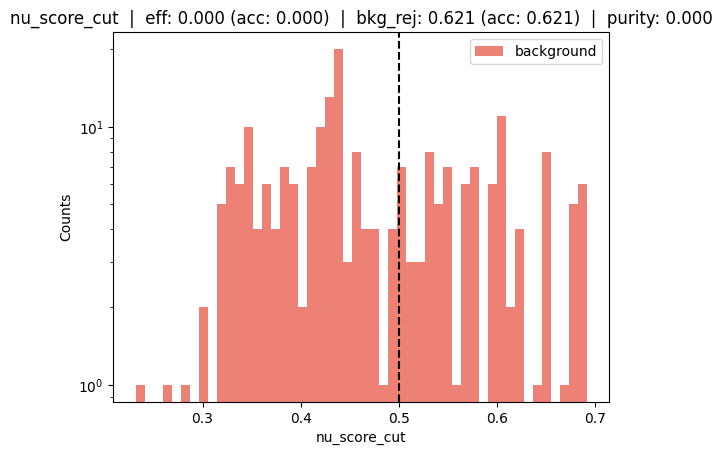

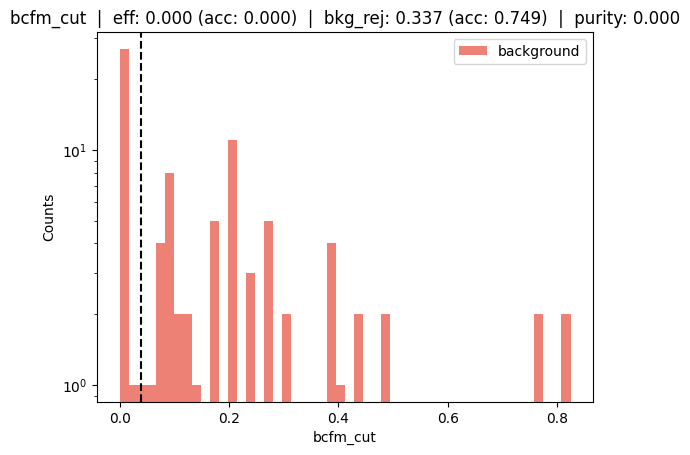

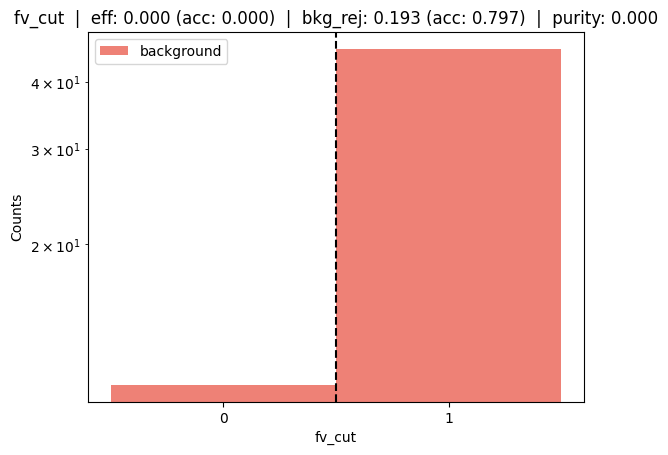

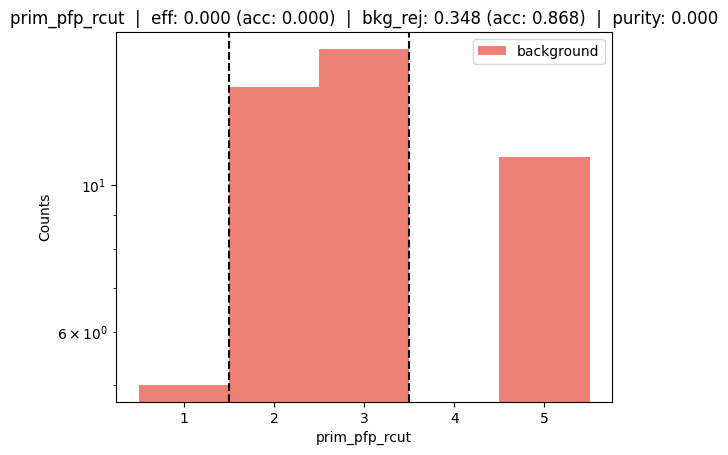

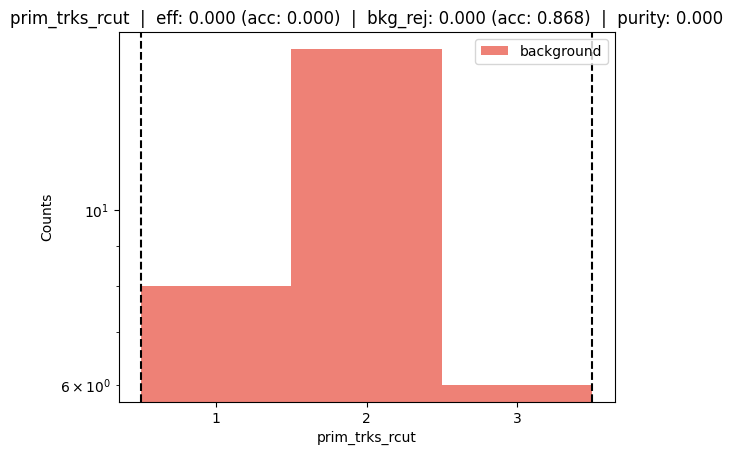

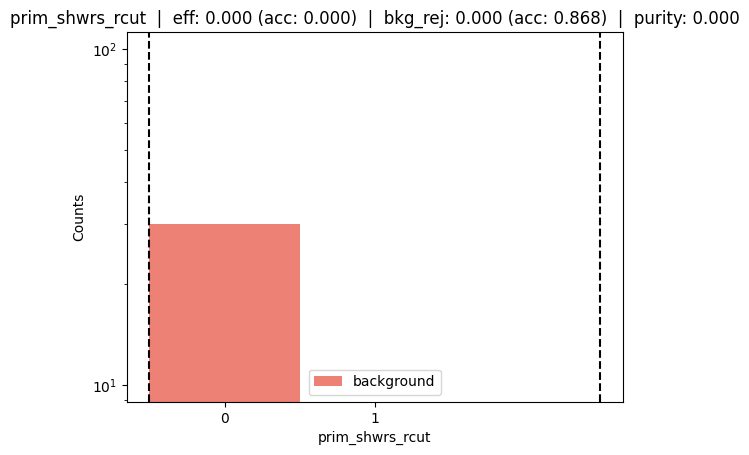

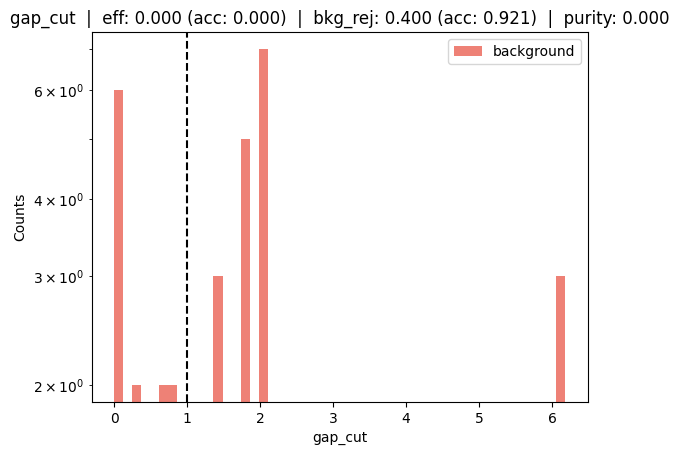

In [94]:
# test

cfg = AnalysisConfig()
driver = AnalysisDriver(pandora_df, cfg)

driver.plot_cuts()


In [198]:
@dataclass
class AnalysisDriver:
    df: pd.DataFrame
    
    # Signal mask — adapt column/value to your data
    signal_mask:    str = "is_signal == 1"
 
    # Background sub-categories: dict of {label: query_string}
    # Leave empty until you know the relevant columns
    bkg_categories: dict = field(default_factory=lambda: {
        # "no_hyperon":   "has_hyperon == 0",
        # "with_hyperon": "has_hyperon == 1",
    })
 
    # Active cuts — append Cut(...) objects as you decide them
    cuts: dict = field(default_factory=lambda: {
        'nu_score_cut' : Cut(('slc', 'nu_score', '', '', '', ''),'>', 0.5)
        'bcfm_cut' : Cut(('slc', 'barycenterFM', 'score', '', '', ''), '>', 0.04)
        'fv_cut' : Cut(('slc', 'in_fv', '','','',''), '==', 1)
        'prim_pfp_rcut' : RangeCut(('slc', 'n_prim_pfps', '','','',''), N_PRIM_PFP_MIN, N_PRIM_PFP_MAX)
        'prim_trks_rcut' : RangeCut(('slc', 'n_prim_trks', '','','',''), N_PRIM_TRKS_MIN, N_PRIM_TRKS_MAX)
        'prim_shwrs_rcut' : RangeCut(('slc', 'n_prim_shwrs', '','','',''), N_PRIM_SHWRS_CUT_MIN, N_PRIM_SHWRS_CUT_MAX)
        'gap_cut' : Cut(('slc', 'min_gap', '','','',''), '>', MIN_GAP),
            })
 
    palette: dict = field(default_factory=lambda: {
        "signal":        "#2ecc71",
        "background":    "#e74c3c",
        "no_hyperon":    "#3498db",
        "with_hyperon":  "#e67e22",
        "other":         "#9b59b6",
    })

    def plot_cuts():
        cuts_acc = [a[:i+1] for i in range(len(cuts))]
        for c_acc in cuts_acc:
            PlotConfig(
                var = '',
                bins = 50,
                title = None,
                xlabel = None,
                ylabel = "Counts",
                weights_col = None,
                colors = [palette[l] for l in labels])
            plot_stack(apply_cuts(df,c_acc.items()), cfg)

    def plot_cuts(self):
        cuts_acc = [a[:i+1] for i in range(len(self.cuts.items()))]
        for i in range(len(cuts_acc)):
            active_cuts = dict(cut_items[:i+1])
            PlotConfig(
                var = '',
                bins = 50,
                title = None,
                xlabel = None,
                ylabel = "Counts",
                weights_col = None,
                colors = [palette[l] for l in labels]
            )
            plot_stack(apply_cuts(self.df, active_cuts), cfg)

            
                 

In [176]:
# ESTAS FUNCIONES NECESITAN UNA VUELTA, EN CUT_SUMMARY LOS DATASETS SALEN DE LA 
# FUNCION SPLIT 
# QUIZA TENER MEJOR UNA UNICA COLUMNA QUE SEPARE LAS DISTINTAS ENTRADAS?


def split(df: pd.DataFrame, cfg: AnalysisConfig) -> dict[str, pd.DataFrame]:
    """Split df into signal + background (+ sub-categories if defined)."""
    sig = df.query(cfg.signal_mask)
    bkg = df.query(f"not ({cfg.signal_mask})")
    datasets = {"signal": sig, "background": bkg}
    for label, query in cfg.bkg_categories.items():
        datasets[label] = bkg.query(query)
    return datasets




def cut_summary(datasets: dict, cuts: list[Cut]) -> pd.DataFrame:
    rows = [{"sample": k,
             "before": len(v),
             "after":  len(apply_cuts(v, cuts)),
             "eff":    f"{len(apply_cuts(v, cuts)) / len(v):.3f}" if len(v) else "—"}
            for k, v in datasets.items()]
    df = pd.DataFrame(rows).set_index("sample")
    print(df.to_string()); return df

In [199]:
nu_score_cut = Cut(('slc', 'nu_score', '', '', '', ''),'>', 0.5)
bcfm_cut = Cut(('slc', 'barycenterFM', 'score', '', '', ''), '>', 0.04)
fv_cut = Cut(('slc', 'in_fv', '','','',''), '==', 1)
prim_pfp_rcut = RangeCut(('slc', 'n_prim_pfps', '','','',''), N_PRIM_PFP_MIN, N_PRIM_PFP_MAX)
prim_trks_rcut = RangeCut(('slc', 'n_prim_trks', '','','',''), N_PRIM_TRKS_MIN, N_PRIM_TRKS_MAX)
prim_shwrs_rcut = RangeCut(('slc', 'n_prim_shwrs', '','','',''), N_PRIM_SHWRS_CUT_MIN, N_PRIM_SHWRS_CUT_MAX)
gap_cut = Cut(('slc', 'min_gap', '','','',''), '>', MIN_GAP)